# Práctica 3.2: Clustering

<center><h3>
    Pablo Pardo Cotos
</h3></center>

## Instrucciones

Esto es un **Jupyter Notebook**, un documento que integra código Python en un archivo Markdown.
Esto nos permite ir ejecutando celdas de código poco a poco, así como generar automáticamente un informe bien formateado de la práctica.

Puedes añadir una celda con el botón **"Insert"** de la barra de herramientas, y cambiar su tipo con **"Cell > Cell Type"**

Para ejecutar una celda de código, la seleccionaremos y pulsaremos el botón **"▶ Run"** de la barra de herramientas.
Para pasar el documento a HTML, seleccionaremos **"File > Download as > HTML (.html)"**

Sigue este guion hasta el final. Ejecuta el código proporcionado paso a paso comprendiendo lo que estás haciendo y reflexionando sobre los resultados. Habrá preguntas intercaladas a lo largo del guion; responde a todas ellas en la sección reservada para ese fin: **"Respuestas al cuestionario"**. Por favor, no modifiques ninguna línea de código excepto cuando se te pida explícitamente.

No olvides insertar tu **nombre y apellidos** en la celda superior.

## Entrega de la práctica

La fecha límite de entrega será la indicada en el Campus Virtual. La entrega consistirá en un único archivo comprimido con el nombre `APELIDOS_NOME_Clustering.zip` que contenga los siguientes ficheros:

 * `APELIDOS_NOME_Clustering.html`: Archivo HTML fruto de la exportación del presente Notebook, con las preguntas respondidas al final del documento.
 * `APELIDOS_NOME_Clustering.ipynb`: Archivo Jupyter Notebook fuente.
 * Archivo de datos del problema de libre elección.

## Números aleatorios

<span style="color:red">**MUY IMPORTANTE:**</span> Vamos a establecer un *seed* con un valor predefinido inmediatamente antes de ejecutar cualquier operación con un componente aleatorio. Así nos aseguraremos de que nuestros resultados sean repetibles.

Esto es, vamos a poner `np.random.seed(SEED_VALUE)` antes de:
 - `train_test_split()`
 - `fit()`
 - `predict()`

También vamos a poner `random_state=SEED_VALUE` en aquellas funciones que lo admitan (como el constructor de `KMeans`).

Habrá ocasiones en las que esto sea excesivo, pero así nos curamos en salud ante despistes.

# Introducción

En esta práctica vamos a reforzar los conceptos vistos en las clases teóricas sobre aprendizaje no supervisado. Comenzaremos trabajando sobre un conjunto de datos ya conocido, el de la superficie y precio de las viviendas, sobre el cual aplicaremos el algoritmo **k-means**. El segundo ejercicio consistirá en aplicar clustering a un problema de libre elección.

# Clustering sobre el dataset de las viviendas

En la práctica anterior fuimos capaces de dar un precio estimado de las viviendas a partir de su superficie. Ahora vamos a usar las dos variables, superficie y precio, para buscar nuevas relaciones entre nuestros datos y hacer una distinción en varias categorías de viviendas.

Cargamos los datos empleando la función `read_csv()`:

In [1]:
import pandas as pd  # Importamos la librería (esto solo es necesario hacerlo una vez)

vivendas = pd.read_csv('vivendas.csv',  # Cargamos el csv
                       delimiter=',',
                       header=0)

En esta práctica no va a ser necesario dividir los datos en dos conjuntos (entrenamiento y test), ya que lo que queremos encontrar son relaciones **nuevas**. Esto implica también que no va a haber ninguna etapa de validación de modelos. En lugar de eso, lo que se suele hacer es una etapa de análisis e interpretación de los agrupamientos obtenidos.

## Agrupamiento empleando funciones propias

___K-means___ es un algoritmo de clasificación no supervisada (*clustering*) que agrupa los ejemplos de un conjunto de datos en $k$ grupos basándose en sus características. El agrupamiento se realiza minimizando la suma de distancias (habitualmente distancia cuadrática) entre cada ejemplo y el centroide del grupo (*cluster*) al que fue asignado.

El algoritmo consta de 3 etapas diferenciadas:

1. **Inicialización**: una vez escogido el número de grupos $k$, se establecen aleatoriamente $k$ centroides en el espacio de datos.
2. **Asignación de los ejemplos a los centroides**: cada instancia del dataset es asignada a su centroide más próximo.
3. **Actualización de los centroides**: para cada grupo, se actualiza la posición del centroide tomando como nuevo centroide la posición media de los ejemplos pertenecientes a dicho grupo.

Los pasos 2 y 3 se repiten durante $n$ iteraciones. El algoritmo resuelve un problema de optimización, siendo la función a optimizar (minimizar) la suma de las distancias cuadráticas de cada ejemplo al centroide de su cluster.

Vamos a emplear las siguientes funciones:

In [66]:
import numpy as np

# Función de distancia cuadrática
def calcula_distancias(a, b):
    matriz_distancias = np.empty([a.shape[0], b.shape[0]])
    # Calculamos la distancia punto a punto de los conjuntos a y b
    for i in range(a.shape[0]):
        for j in range(b.shape[0]):
            diff = a[i] - b[j]
            matriz_distancias[i, j] = np.sqrt(diff[0] ** 2 + diff[1] ** 2)

    return matriz_distancias

# Función a optimizar J
def j(x, centroides, clusters):
    # Obtenemos la distancia de cada punto a su cluster
    distancias = x - centroides[clusters]
    # Calculamos el coste 
    custo = 1.0/x.shape[0] * sum(np.sqrt(distancias[:, 0]**2 + distancias[:,1]**2))
    return custo

# Función de actualización de centroides
def actualiza_centr(x, clusters, centroides):
    # Para cada uno de los centroides
    for i in range(centroides.shape[0]):
        # Tomamos los x dentro de su cluster correspondiente
        x_cluster_i = x[clusters==i]
        # Hacemos la media de todos los puntos del cluster y esa es su nueva ubicación 
        centroides[i] = np.sum(x_cluster_i, axis=0)/x_cluster_i.shape[0]

    return centroides


# Función de clustering k-means
def k_medias(x, centroides, iteracions):
    hist_clusters = []
    hist_centroides = []
    hist_custo = []

    for i in range(iteracions):
        dist_centroides = calcula_distancias(x, centroides)
        clusters = np.argmin(dist_centroides, axis=1)
        centroides = actualiza_centr(x, clusters, centroides)
        custo = j(x, centroides, clusters)
        # Guardamos el historial de cada iteración
        hist_clusters.append(clusters)
        hist_centroides.append(centroides.copy())
        hist_custo.append(custo)

    return {'custo': hist_custo, 'clusters': hist_clusters, 'centroides': hist_centroides}

Ya podemos realizar un primer agrupamiento. Convertimos el dataset a una matriz porque en este caso nos facilita las operaciones:

In [3]:
vivendas_mat = vivendas.values

Tomamos 3 ejemplos al azar como centroides iniciales (no debemos olvidarnos de definir una semilla para que los resultados sean repetibles):

In [4]:
SEED_VALUE = 190463  # NO CAMBIES ESTE SEED, así todos tendremos los mismos resultados

np.random.seed(SEED_VALUE)
centroides_iniciais = vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]
centroides_iniciais

array([[210.  , 299.9 ],
       [106.  , 104.96],
       [ 76.  ,  80.15]])

Invocamos el método `k_medias`:

In [5]:
# Definimos el número de iteraciones del algoritmo
n_iter = 20
# Invocamos el método k_medias
agrupamento_1 = k_medias(vivendas_mat, centroides_iniciais, n_iter)

La variable `agrupamento_1` almacena el historial de costes, los centroides y las asignaciones de cada ejemplo a los 3 clusters en todas las iteraciones. Aquí tienes algunos ejemplos de la información a la que puedes acceder:

In [6]:
# Coste tras la primera iteración
agrupamento_1['custo'][0]

np.float64(44.57248682542861)

In [7]:
# Coste final
agrupamento_1['custo'][n_iter-1]

np.float64(39.661108023599255)

In [8]:
# Centroides en la iteración 4
agrupamento_1['centroides'][3]

array([[208.57142857, 351.38357143],
       [126.61538462, 157.60307692],
       [ 93.87878788,  86.56242424]])

In [9]:
# Asignación de los 6 primeros ejemplos del dataset a los clusters en la última iteración
agrupamento_1['clusters'][n_iter-1][:6]

array([2, 1, 1, 2, 1, 2])

Vamos a graficar paso a paso cómo fue convergiendo el algoritmo para llegar al agrupamiento definitivo:

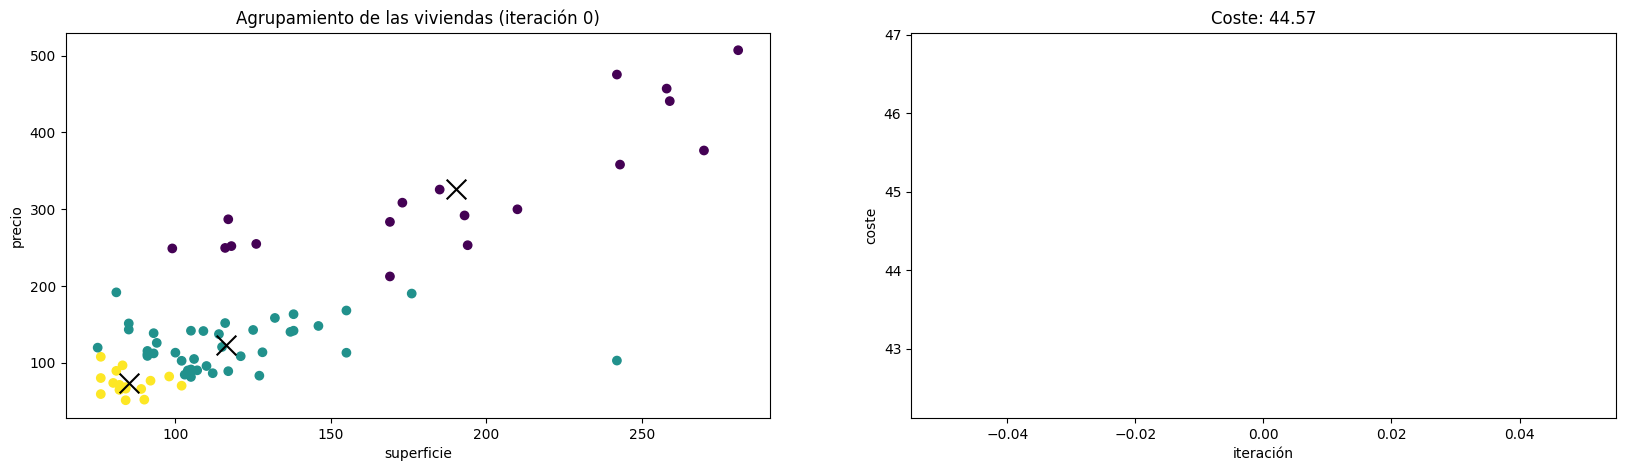

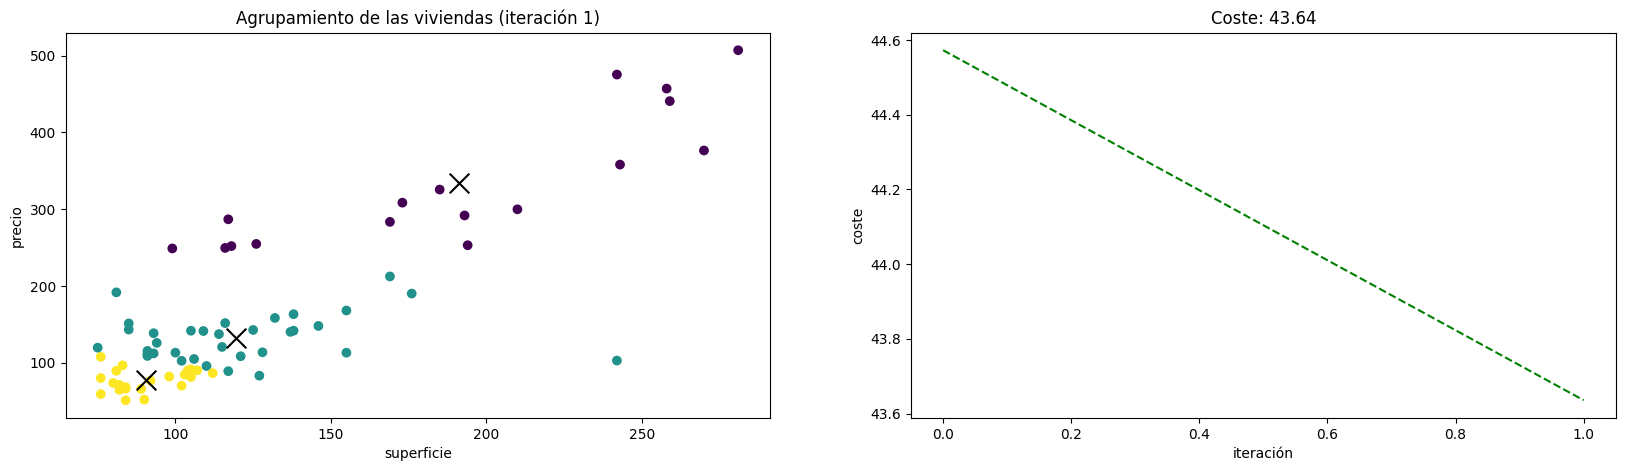

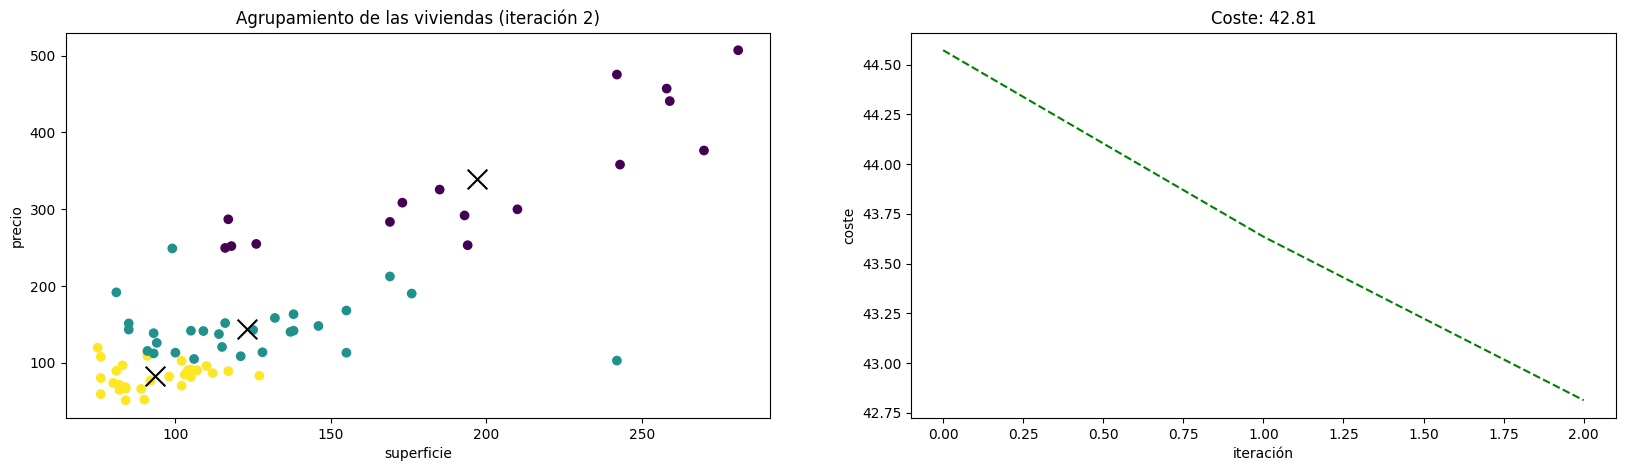

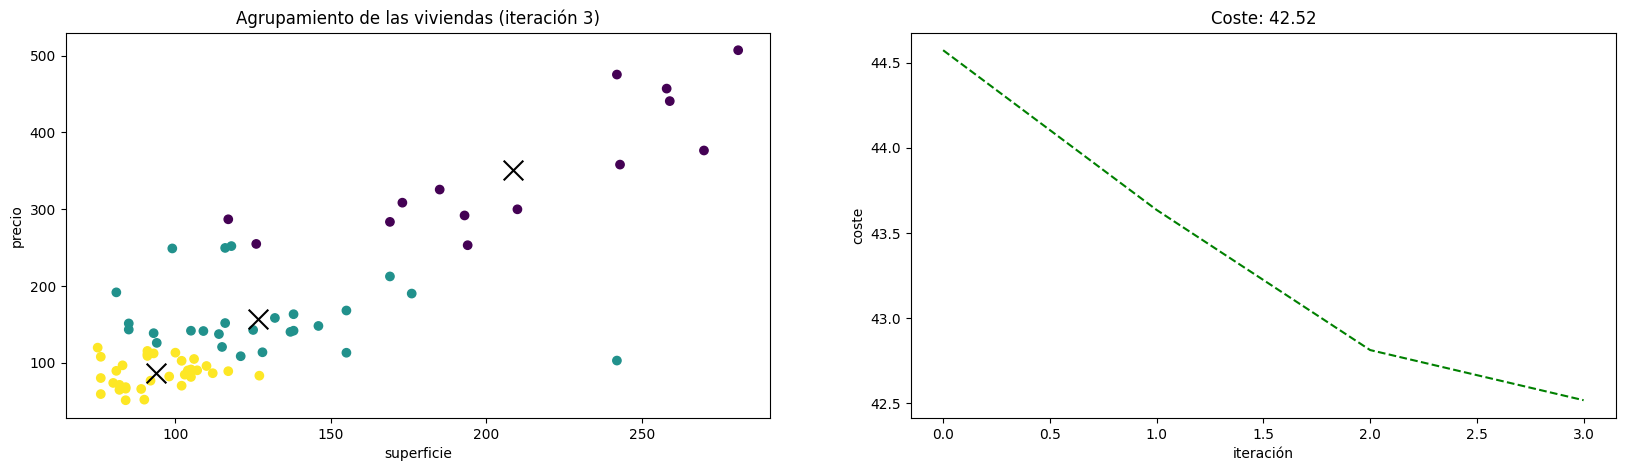

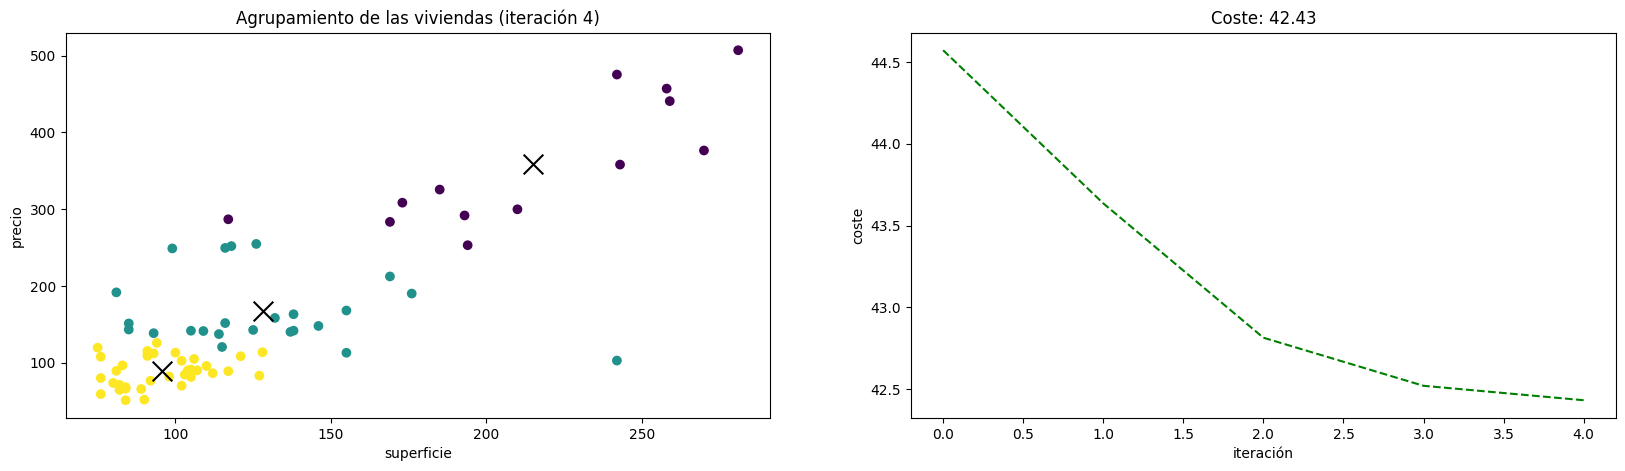

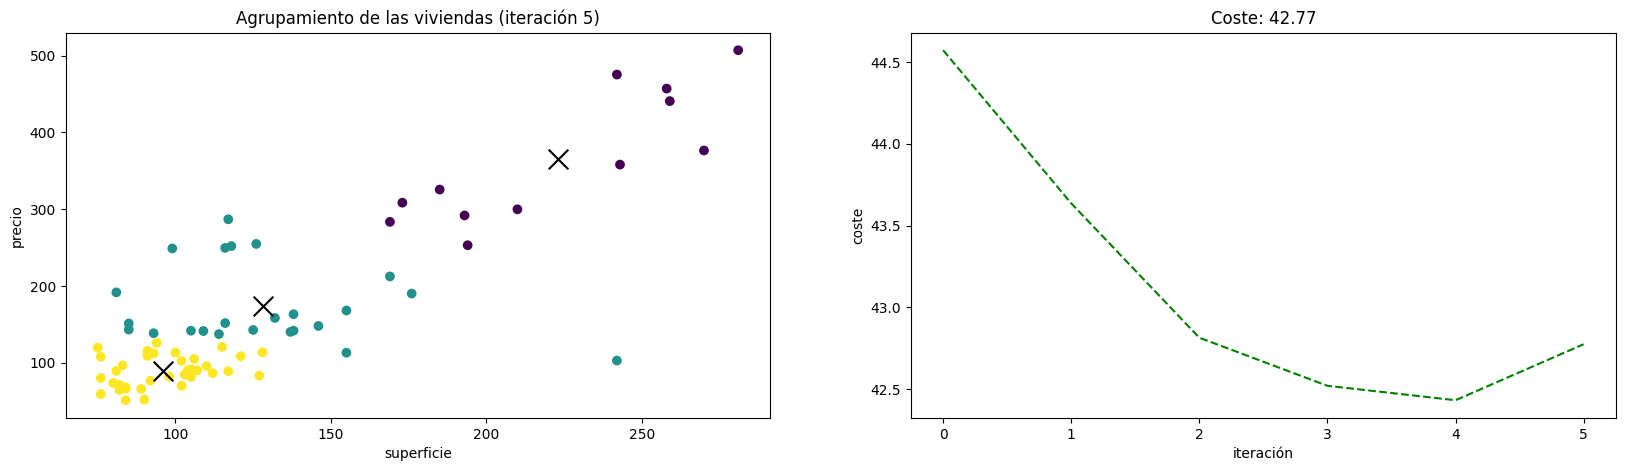

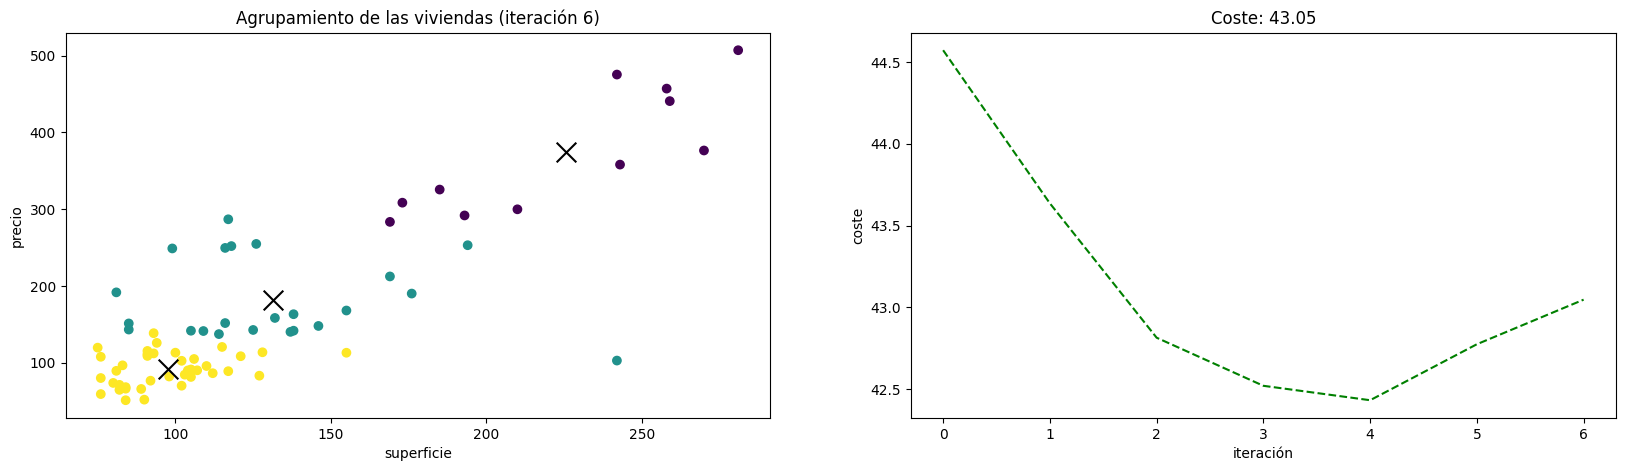

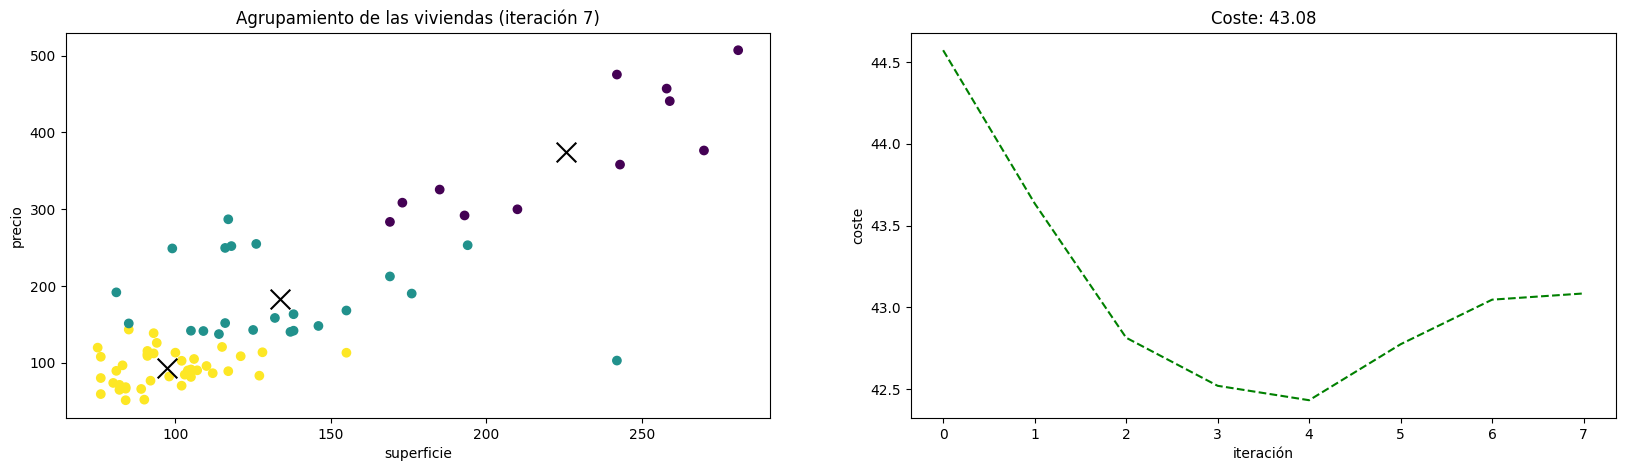

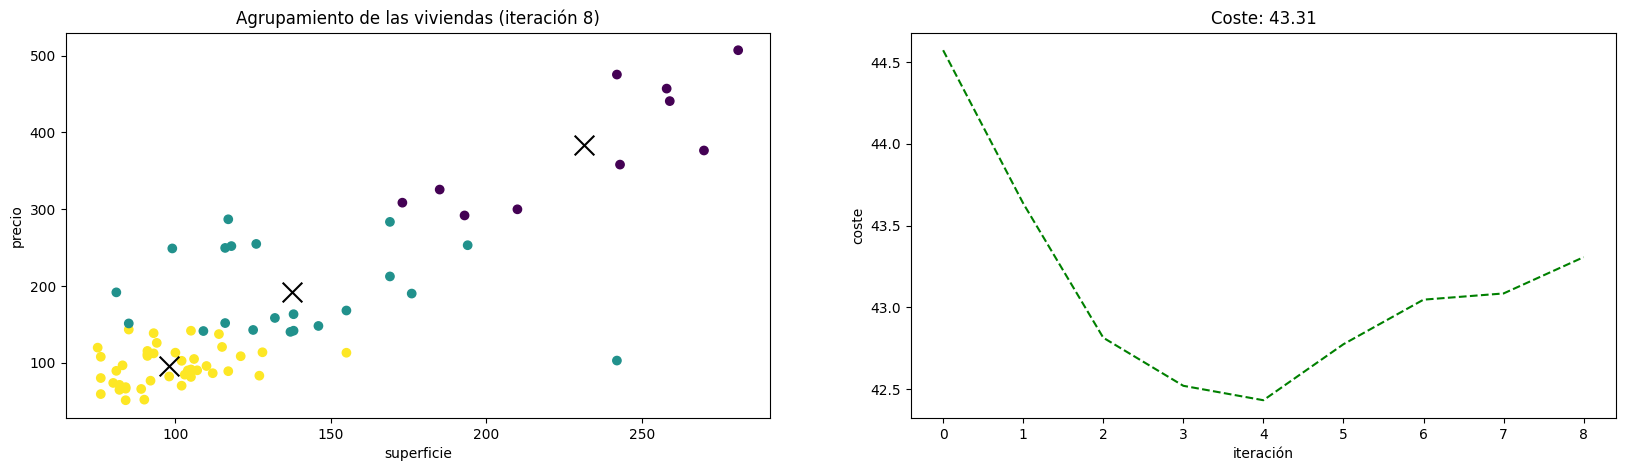

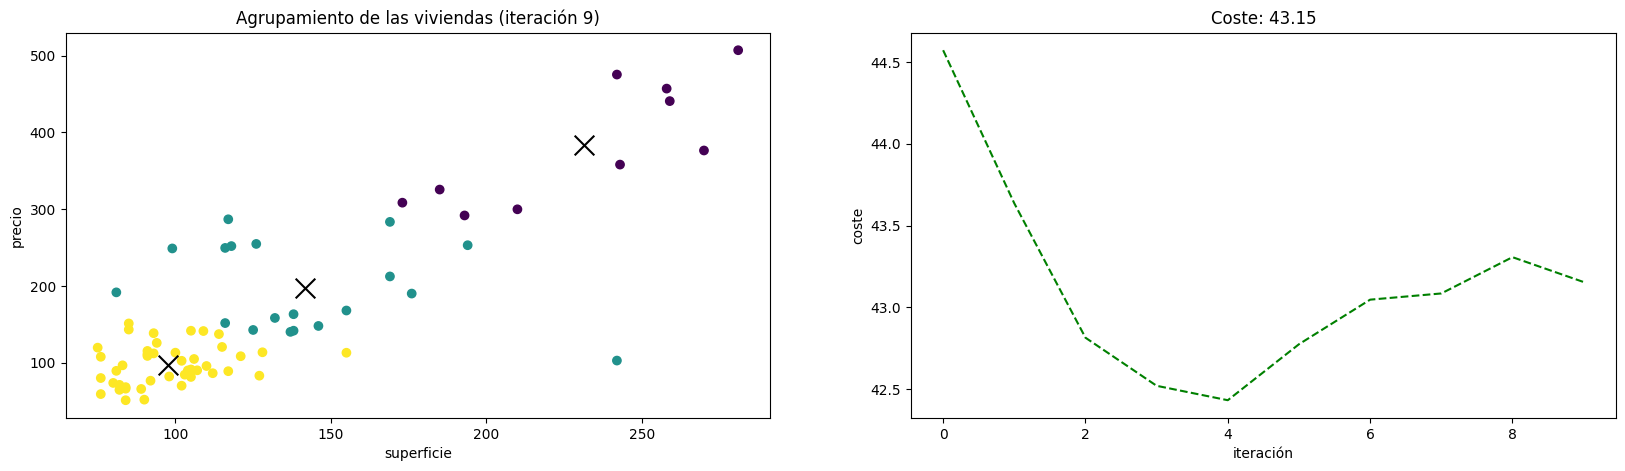

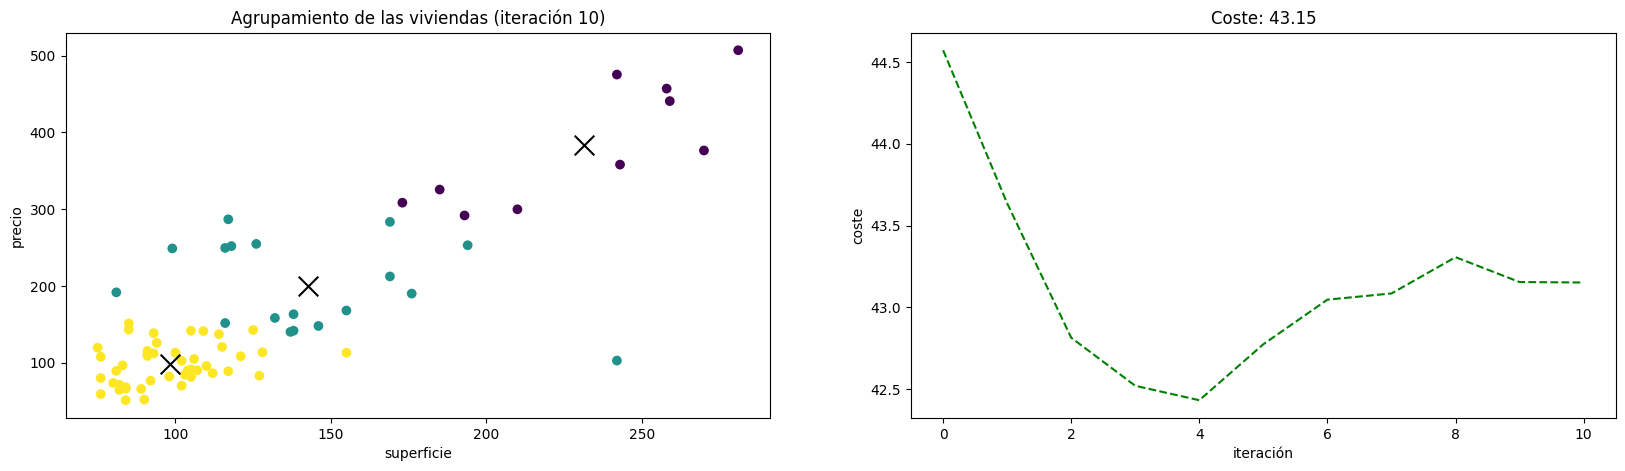

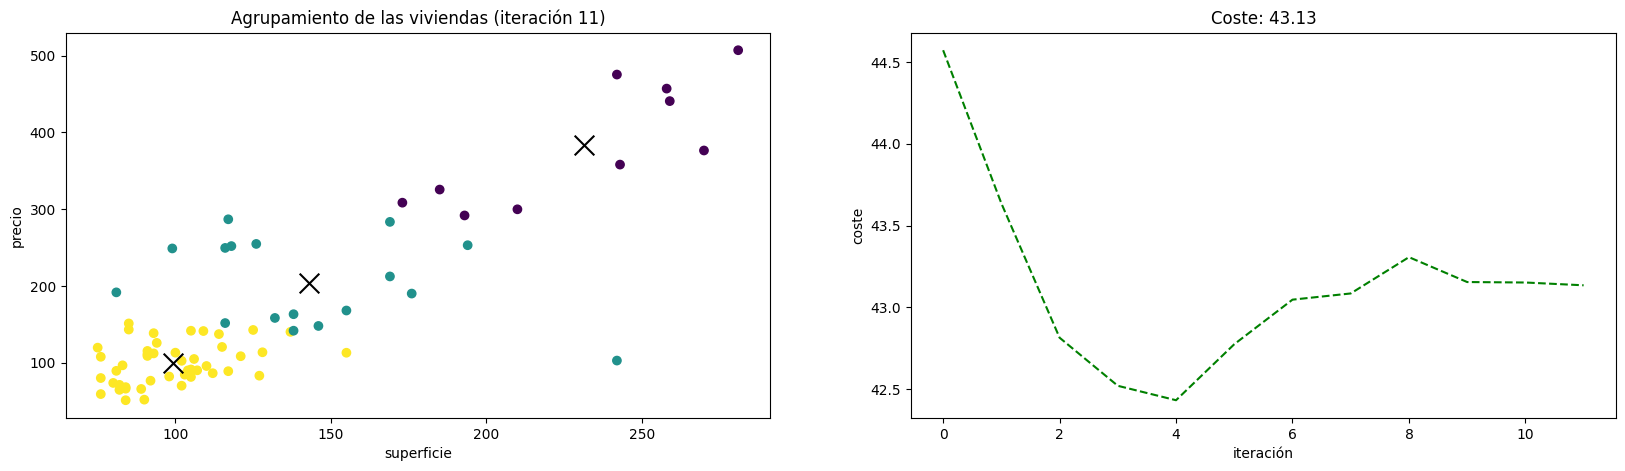

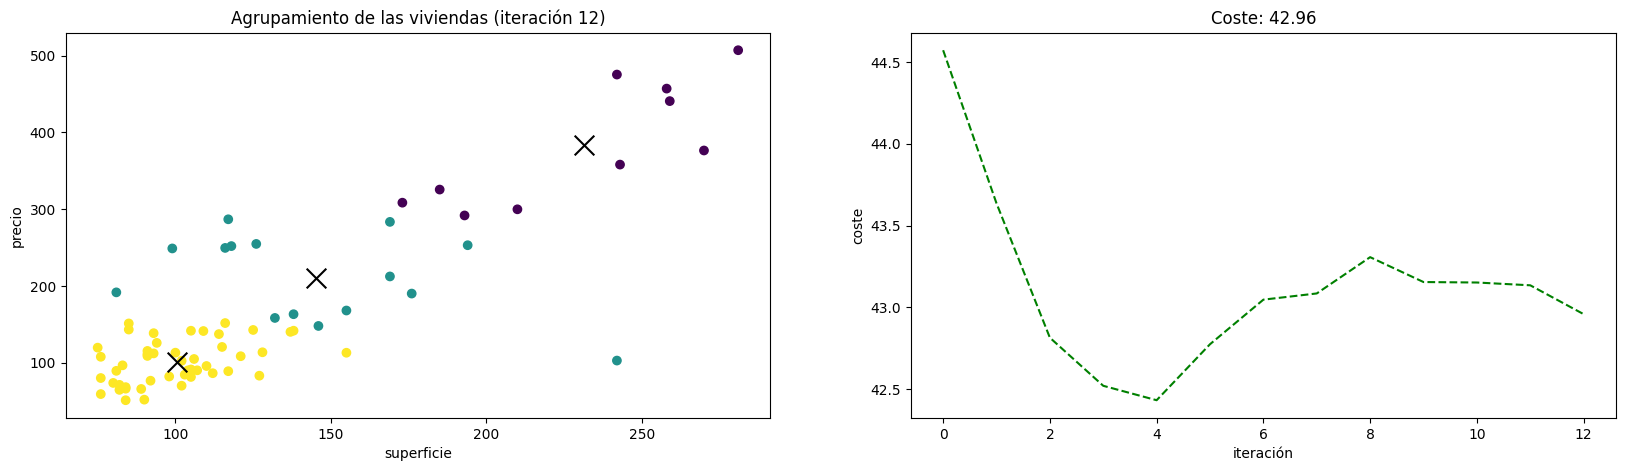

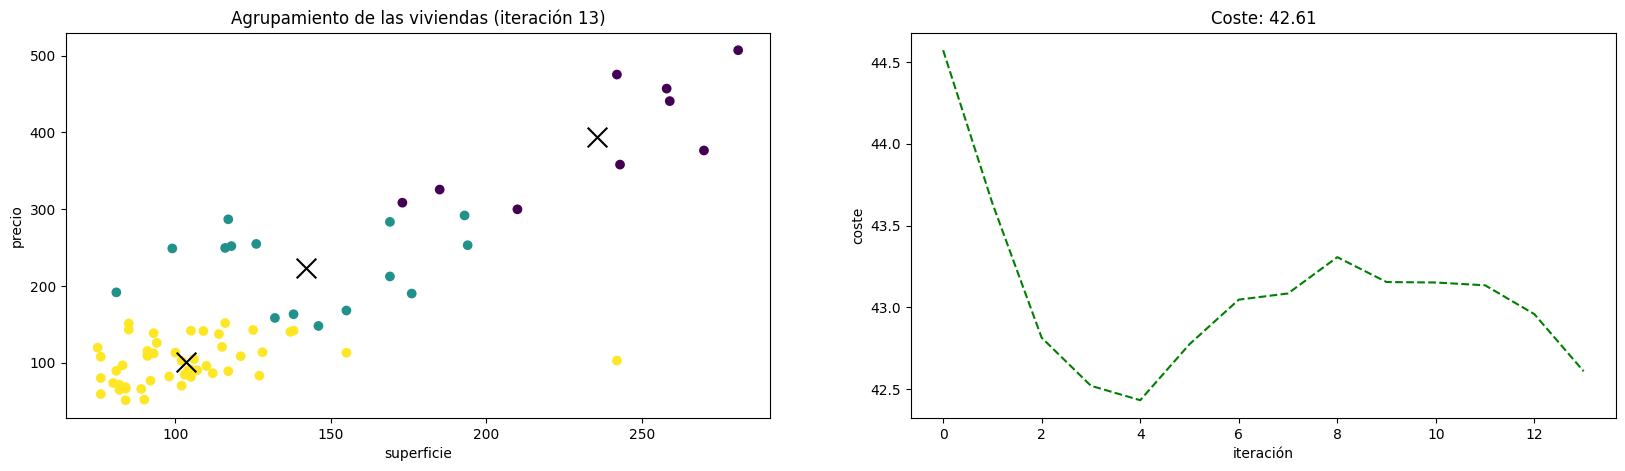

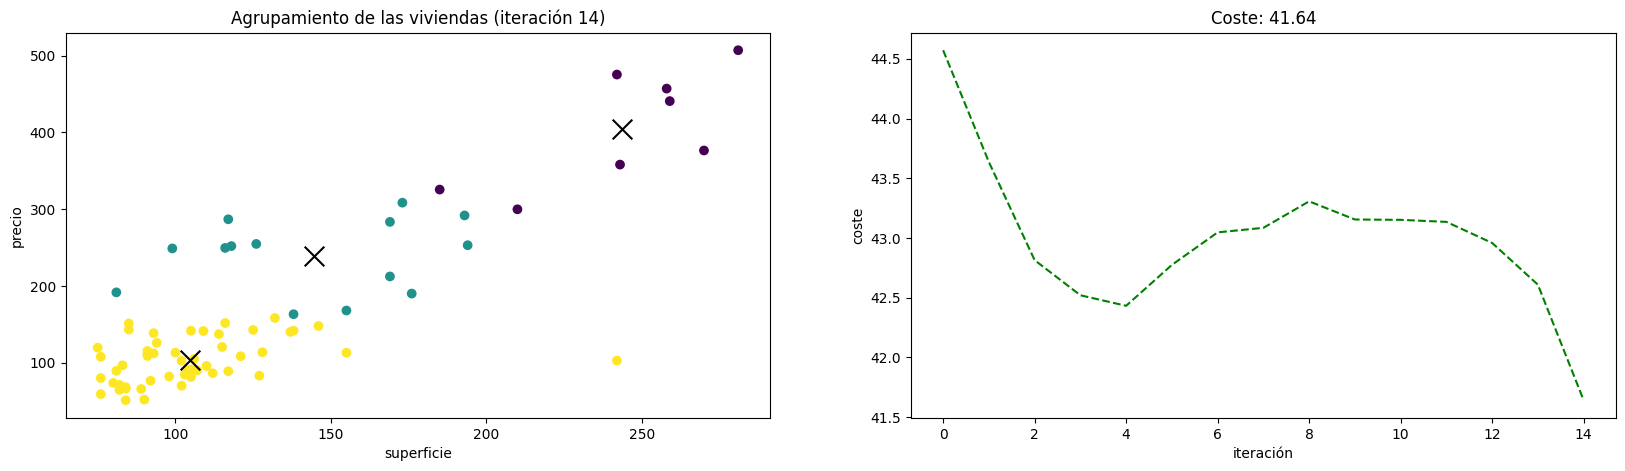

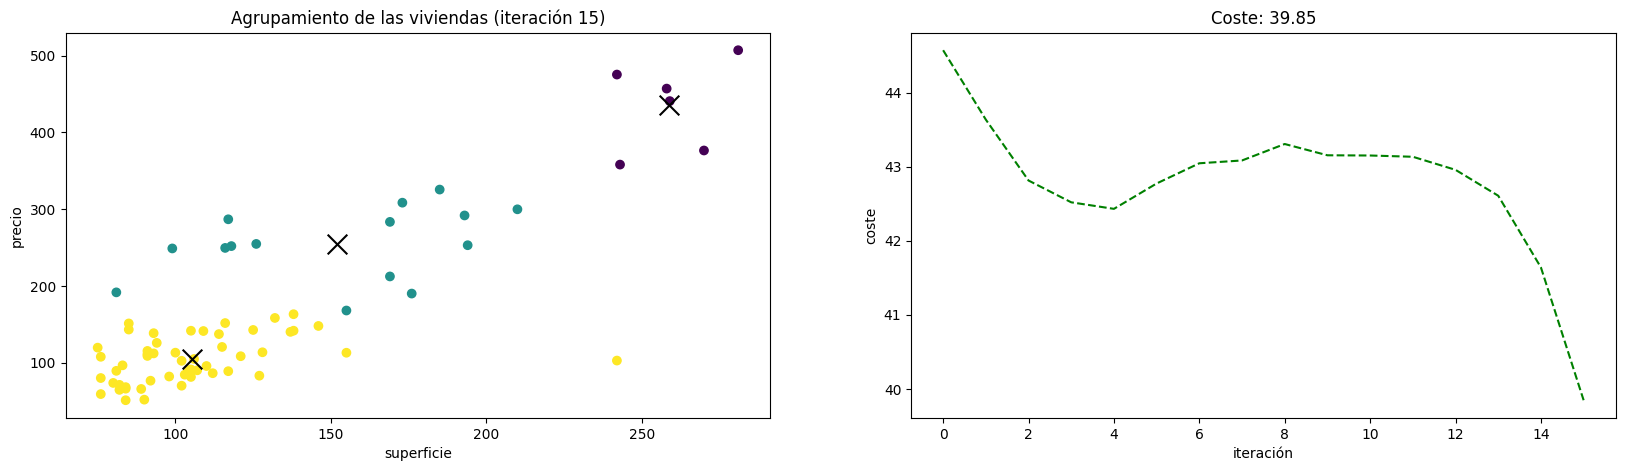

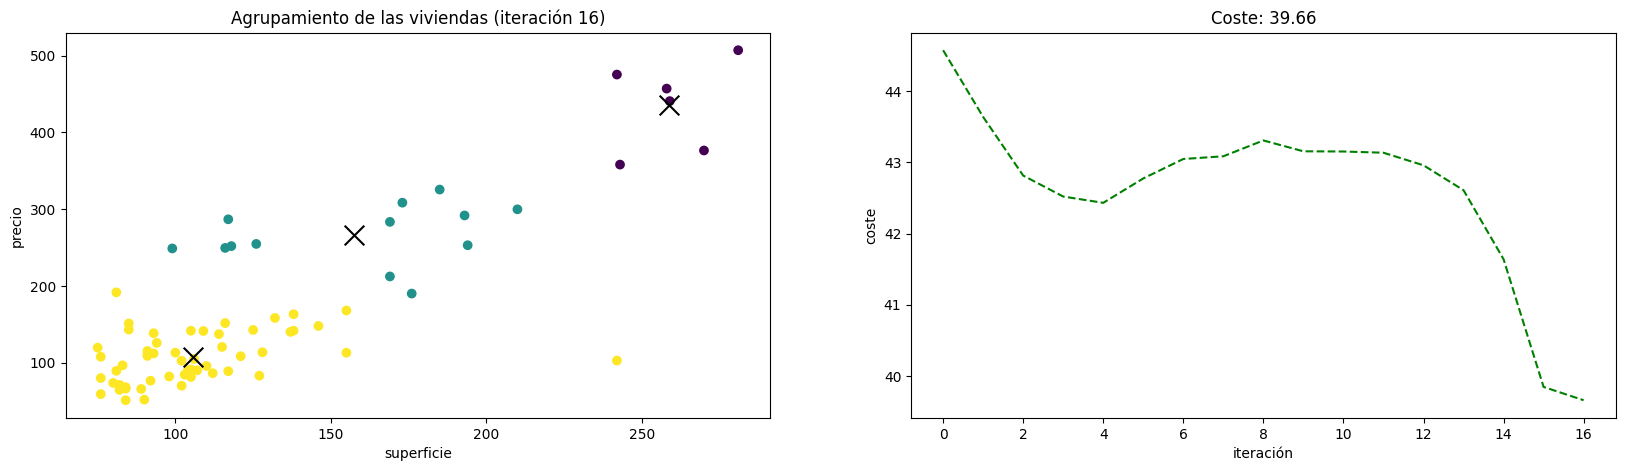

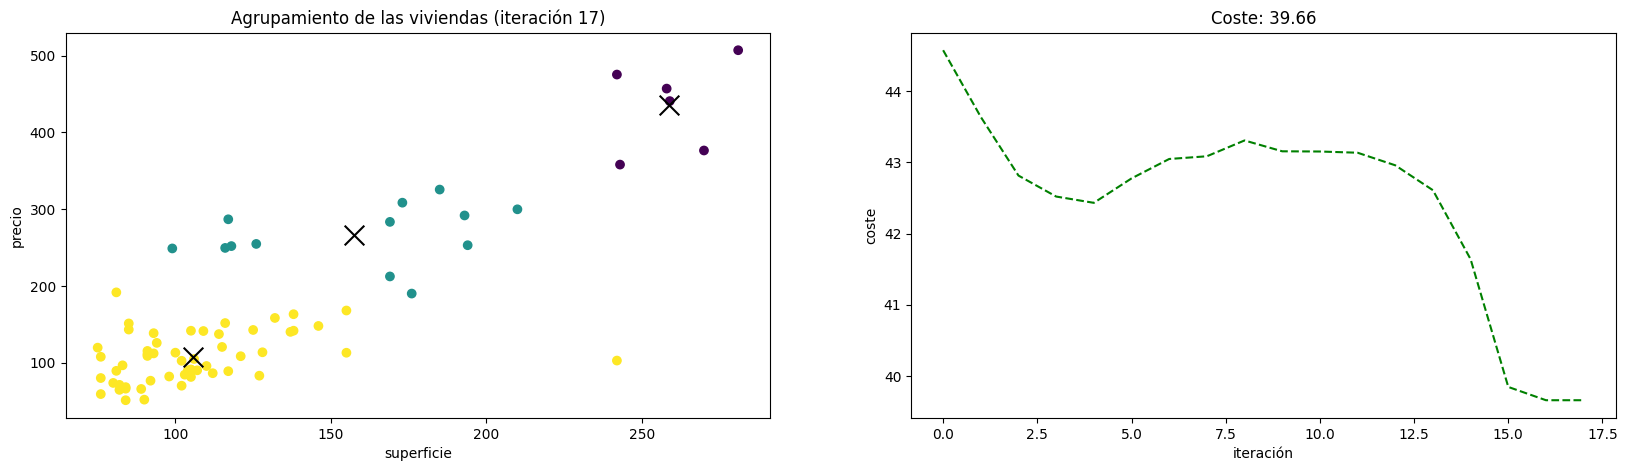

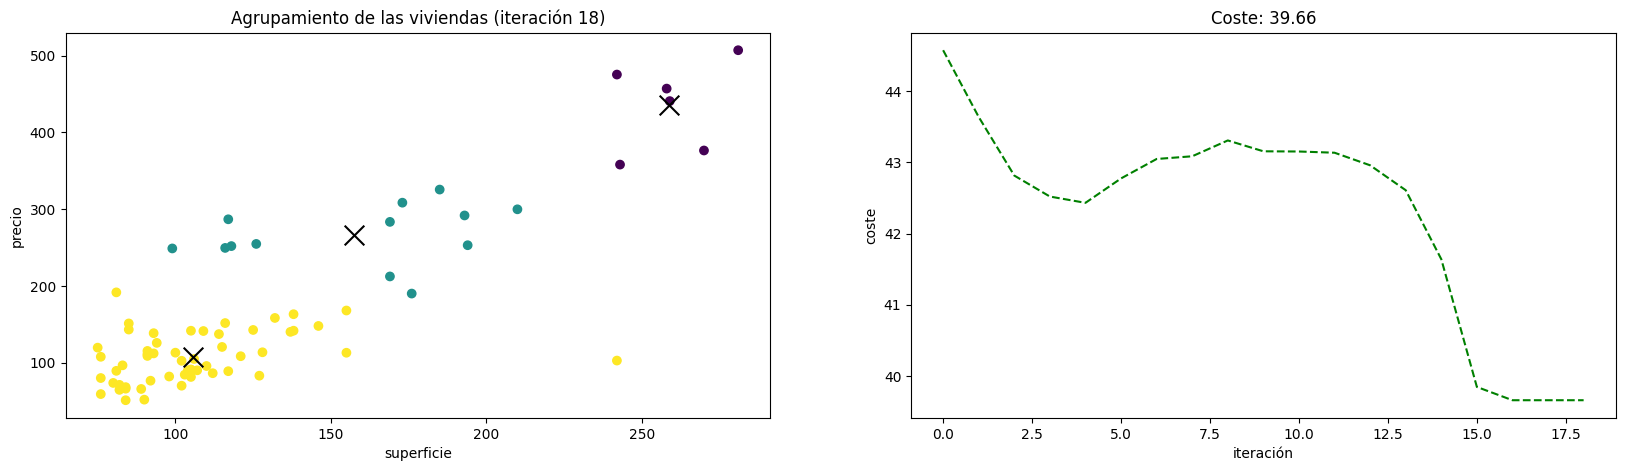

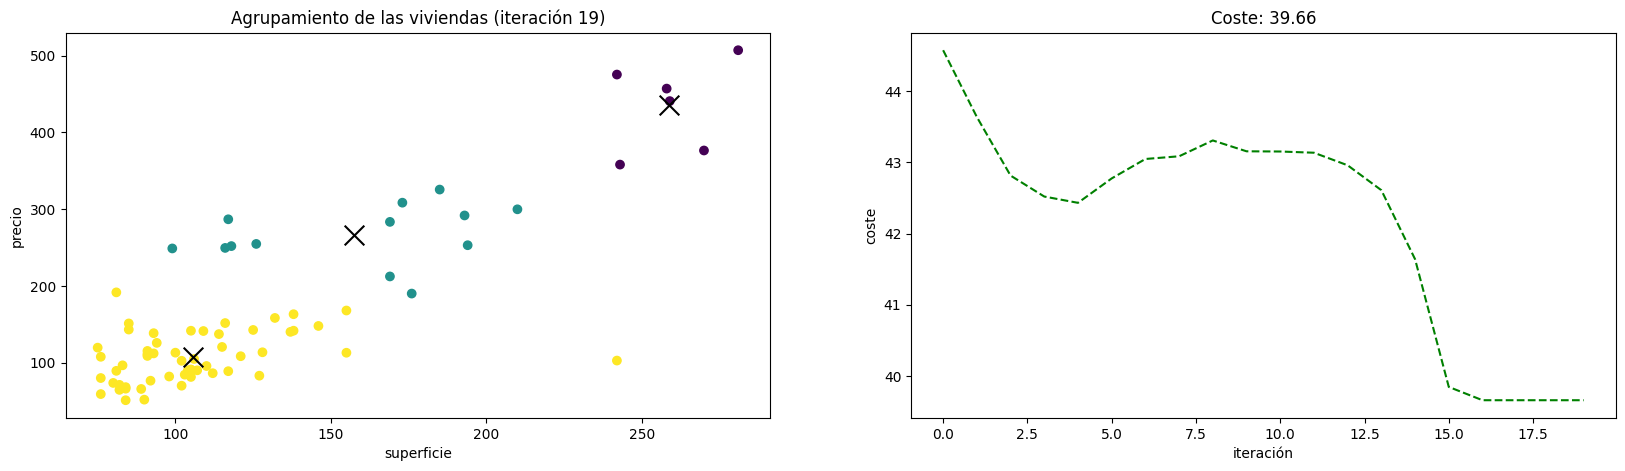

In [10]:
import matplotlib.pyplot as plt

for i in range(n_iter):
    fig = plt.figure(figsize=(20, 5))  # Creamos una figura (contenedor para elementos a dibujar)
    ax1 = fig.add_subplot(121, projection='rectilinear')  # Añadimos Axes a la figura (contiene los elementos del dibujo, queremos una matriz [1,2])
    ax2 = fig.add_subplot(122, projection='rectilinear')

    # Añadimos los scatterplots
    ax1.scatter(vivendas['superficie'], vivendas['prezo'], c=agrupamento_1['clusters'][i])  # Viviendas
    ax1.scatter(agrupamento_1['centroides'][i][:, 0], agrupamento_1['centroides'][i][:, 1],
                s=200, marker='x', color='black')  # Centroides
    ax1.set_title("Agrupamiento de las viviendas (iteración {})".format(i))  # Ponemos un título
    ax1.set_xlabel("superficie")  # Nombramos los ejes
    ax1.set_ylabel("precio")

    # Añadimos los costes
    ax2.plot(range(i+1), agrupamento_1['custo'][:i+1], '--', color="green")
    ax2.set_title("Coste: {:.2f}".format(agrupamento_1['custo'][i]))  # Ponemos un título
    ax2.set_xlabel("iteración")  # Nombramos los ejes
    ax2.set_ylabel("coste")


    plt.show()  # Mostramos la figura por pantalla

En las figuras anteriores, la gráfica de la izquierda indica siempre el agrupamiento realizado. Los ejemplos del conjunto de datos se colorean de distinto color en función del cluster al que son asignados. Las **x** con una circunferencia alrededor ubican los centroides. En la gráfica de la derecha tenemos la evolución del coste ($J$) en las sucesivas iteraciones, tal y como hacíamos en regresión lineal.

Ahora que has visto el proceso de clustering paso a paso, trata de responder a las siguientes cuestiones.

> ❓ **_Pregunta 1._**  Recuerda que en la práctica anterior el coste venía dado por el error cuadrático medio de las diferencias entre cada predicción y el valor del precio real. ¿Cómo estimamos el coste en el caso del aprendizaje no supervisado con k-means?

> ❓ **_Pregunta 2._**  Explica qué es la salida de la función `calcula_distancias`.

> ❓ **_Pregunta 3._**  Explica qué contiene `x_cluster_i` y qué es lo que hace la expresión `np.sum(x_cluster_i, axis=0)/x_cluster_i.shape[0]` en la función `actualiza_centr`.

> ❓ **_Pregunta 4._**  Identifica en el código de los scripts anteriores dónde se realizan cada una de las 3 etapas de k-means (inicialización, asignación de los datos a los clusters y actualización de los centroides).

### Inicialización aleatoria múltiple de los centroides

Si cambiamos los centroides iniciales, el algoritmo puede no converger a los mismos resultados.

In [11]:
SEED_VALUE = 22634  # NO CAMBIES ESTE SEED, así todos tendremos los mismos resultados

np.random.seed(SEED_VALUE)
centroides_iniciais_2 = vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]
centroides_iniciais_2

array([[259.  , 440.83],
       [ 81.  ,  89.52],
       [126.  , 254.81]])

In [12]:
# Realizamos un nuevo agrupamiento
agrupamento_2 = k_medias(vivendas_mat, centroides_iniciais_2, n_iter)

En este caso, puesto que el problema es pequeño y sencillo, 20 iteraciones son más que suficientes para converger al agrupamiento óptimo, sean cuales sean los centroides de arranque:

In [13]:
# Centroides finales del primer agrupamiento
agrupamento_1['centroides'][n_iter-1]

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

In [14]:
# Centroides finales del segundo agrupamiento
agrupamento_2['centroides'][n_iter-1]

array([[258.83333333, 435.845     ],
       [105.77777778, 107.42740741],
       [157.30769231, 265.95846154]])

Fíjate en que, aunque en esencia los resultados son los mismos que en el primer agrupamiento, los centroides 2 y 3 están intercambiados, por lo que técnicamente la solución a la que llega el algoritmo es otra (y, sin embargo, todo el proceso iterativo fue distinto).

En muchos problemas reales los resultados cambiarán mucho en función de cómo inicialicemos los centroides. Incluso en el problema de las viviendas, si el número de iteraciones es más pequeño (por ejemplo, 10), no siempre se alcanzará el óptimo global. Por ello se suelen realizar múltiples ($m$) inicializaciones aleatorias de los centroides. La siguiente función es una extensión de la función base `k_medias` que permite ejecutar k-means para $m$ inicializaciones distintas de los centroides y un valor $k$ constante:

In [ ]:
# Función k-means de inicialización aleatoria múltiple
def k_medias_multi_ini(x, n, m, k):
    x_mat = x.values 
    custos_finais = []
    centroides_finais = []
    clusters_finais = []
    for i in range(m):
        ## Devuelve las filas que estén entre np.random.choice(x_mat.shape[0] y k
        centr_iniciais = x_mat[np.random.choice(x_mat.shape[0], size=k, replace=False)]
        ## Se produce el algoritmo de las k_medias
        agrupamento = k_medias(x_mat, centr_iniciais, n)
        custos_finais.append(agrupamento['custo'][n-1])
        centroides_finais.append(agrupamento['centroides'][n-1])
        clusters_finais.append(agrupamento['clusters'][n-1])

    custo_minimo = min(custos_finais)
    indice_mellor = np.argmin(custos_finais)
    centroides_mellor = centroides_finais[indice_mellor]
    clusters_mellor = clusters_finais[indice_mellor]

    return {'custo_minimo': custo_minimo, 'mellor_iteracion': indice_mellor,
            'mellores_centroides': centroides_mellor, 'mellor_asignacion': clusters_mellor}

Vamos a probar la función anterior:

In [16]:
SEED_VALUE = 134  # NO CAMBIES ESTE SEED, así todos tendremos los mismos resultados
np.random.seed(SEED_VALUE)

m_ini = 10
n_iter = 15
k_cent = 3
agrupamento_3 = k_medias_multi_ini(x=vivendas, n=n_iter, m=m_ini, k=k_cent)

In [17]:
# Mejor iteración
agrupamento_3['mellor_iteracion']

np.int64(5)

In [18]:
# Mejores centroides
agrupamento_3['mellores_centroides']

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

In [19]:
# Asignación del mejor cluster para cada uno de los 6 primeros ejemplos del dataset:
agrupamento_3['mellor_asignacion'][:6]

array([2, 1, 1, 2, 1, 2])

> ❓ **_Pregunta 5._**  ¿Qué devuelve la salida de la función `k_medias_multi_ini`? ¿Cómo se eligen los mejores centroides?

### Selección del número de centroides

Por ahora hemos mantenido el valor de $k$ constante, haciendo siempre agrupamientos en 3 clusters. Una pregunta que te podría surgir a estas alturas es cómo saber cuál es el número de centroides más adecuado. La selección del $k$ óptimo es a menudo ambigua, con interpretaciones que dependen de la forma y la escala de la distribución de puntos en el conjunto de datos. Aumentar el $k$ sin penalización siempre reducirá el valor del coste en la agrupación resultante, hasta el caso extremo de coste cero si cada punto de los datos se considera como su propio agrupamiento (es decir, cuando $k$ es igual al número de ejemplos del conjunto de datos). Intuitivamente, la elección óptima de $k$ alcanzará un equilibrio entre la compresión máxima de los datos utilizando un solo cluster y la máxima precisión al asignar cada instancia a su propio cluster.

Cuando el valor apropiado de $k$ no es evidente a partir del conocimiento previo de las propiedades del conjunto de datos, existen métodos que nos ayudan a tomar esta decisión. Uno de los más sencillos es el **método del codo** (en inglés, *elbow method*), el cual analiza la reducción del coste en función del número de clusters: debe elegirse aquel número de clusters tal que, al añadir otro cluster más, no se alcancen resultados mucho mejores. De un modo más formal, si se grafica el coste obtenido en función de $k$, los primeros agrupamientos tendrán un error alto por agrupar muchos datos en pocos clusters, pero en algún momento la ganancia marginal caerá, provocando un "codo" en el gráfico. El número de clusters se fija en este punto, de ahí el nombre del método.

El siguiente script ejecuta el método `k_medias_multi_ini` para distintos valores de $k$ (el mínimo es $k=2$):

In [20]:
SEED_VALUE = 42  # NO CAMBIES ESTE SEED, así todos tendremos los mismos resultados
np.random.seed(SEED_VALUE)

k_max = 10
m_ini = 10
n_iter = 20
custos_finais = []
centroides_finais = []
clusters_finais = []
for k in range(2, k_max+1):
    agrupamento = k_medias_multi_ini(x=vivendas, n=n_iter, m=m_ini, k=k)
    custos_finais.append(agrupamento['custo_minimo'])
    centroides_finais.append(agrupamento['mellores_centroides'])
    clusters_finais.append(agrupamento['mellor_asignacion'])

> ❓ **_Pregunta 6._**  ¿Cuántas veces se ejecuta el algoritmo k-means en el script anterior?

Ahora vamos a aplicar el método del codo para determinar el número óptimo de clusters. Para ello, graficamos la evolución del coste en función de $k$:

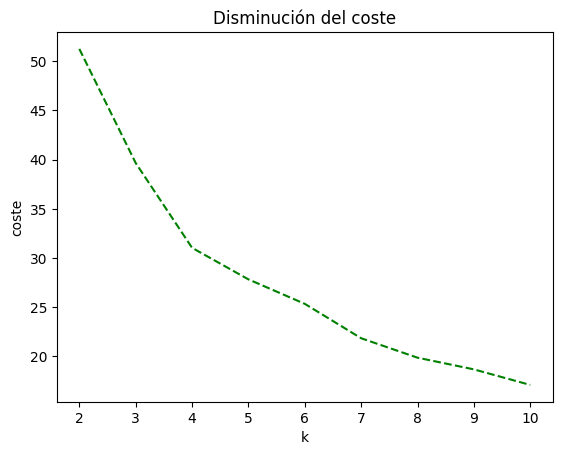

In [21]:
plt.plot(range(2, k_max+1), custos_finais, '--', color="green")
plt.title("Disminución del coste")
plt.xlabel("k")
plt.ylabel("coste")
plt.show()

A simple vista se puede apreciar que el "codo" de la función está en $k=4$. A partir de este valor la mejora que obtenemos es mucho menos significativa. Por tanto, podemos asumir que el número de clusters ideal es 4:

In [22]:
k_mellor = 4

# Centroides para el mejor k (4)
centroides_mellor = centroides_finais[k_mellor-2]  # Hay que tener en cuenta que la lista comienza en 2
centroides_mellor

array([[ 93.87878788,  86.56242424],
       [126.81818182, 142.48545455],
       [155.75      , 272.275     ],
       [258.83333333, 435.845     ]])

In [23]:
# Asignación del mejor cluster para cada uno de los 6 primeros ejemplos del dataset
clusters_mellor = clusters_finais[k_mellor-2]  # Hay que tener en cuenta que la lista comienza en 2
clusters_mellor[:6]

array([1, 2, 2, 1, 2, 0])

Graficamos el último agrupamiento, que vamos a considerar el definitivo:

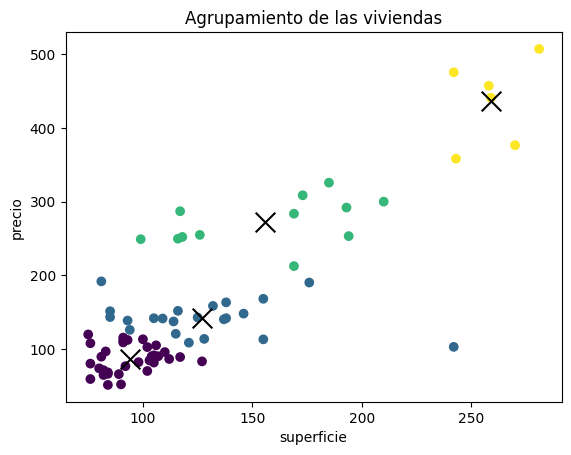

In [24]:
fig = plt.figure()  # Creamos una figura (contenedor para elementos a dibujar)
ax1 = fig.add_subplot(111, projection='rectilinear')  # Añadimos Axes a la figura (contiene los elementos del dibujo)

# Añadimos los scatterplots
ax1.scatter(vivendas['superficie'], vivendas['prezo'], c=clusters_mellor)  # Viviendas
ax1.scatter(centroides_mellor[:, 0], centroides_mellor[:, 1], s=200, marker='x', color='black')  # Centroides

ax1.set_title("Agrupamiento de las viviendas")  # Ponemos un título
ax1.set_xlabel("superficie")  # Nombramos los ejes
ax1.set_ylabel("precio")

plt.show()  # Mostramos la figura por pantalla

### Interpretación de los resultados

Quedaría ahora una última etapa de análisis e interpretación de los resultados. Habrá situaciones (como esta) donde la interpretación sea bastante trivial. Sin embargo, en muchos problemas reales donde se trabaja con un mayor número de variables (y por tanto ya no estamos hablando de interpretar un simple gráfico 2D) puede resultar muy complejo lograr atribuirle un significado a los grupos formados.

> ❓ **_Pregunta 7._**  Haz una breve interpretación de los clusters obtenidos.

## Agrupamiento con la función `KMeans`

Una vez más, `scikit-learn` nos facilita las tareas de clustering proporcionándonos paquetes y funciones muy útiles. Una de las funciones imprescindibles es `KMeans`. En el siguiente script vamos a volver a obtener el primero de los agrupamientos que realizamos en el ejercicio anterior, pero invocando a `KMeans` en lugar de `k_medias`:

In [25]:
from sklearn.cluster import KMeans

# Definimos el número de iteraciones
n_iter = 20

# Obtenemos los mismos centroides iniciales que antes
SEED_VALUE = 190463  # NO CAMBIES ESTE SEED, así todos tendremos los mismos resultados
np.random.seed(SEED_VALUE)
centr_iniciais = vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]

# Definimos el modelo
# NOTA: el enunciado usa algorithm='full', que scikit-learn eliminó en la versión 1.3
# (con la 1.9 da error). 'lloyd' es el nuevo nombre del mismo algoritmo.
model = KMeans(n_clusters=len(centr_iniciais), init=centr_iniciais, n_init=1,
               max_iter=n_iter, algorithm='lloyd', random_state=SEED_VALUE)

# Ajustamos el modelo a los datos
np.random.seed(SEED_VALUE)
agrupamento_4 = model.fit(vivendas)

El argumento `algorithm="full"` (ahora `"lloyd"`) simplemente nos asegura que por debajo estamos empleando el mismo método que el que implementamos en el ejercicio anterior (hay varias implementaciones, puedes consultarlas en la ayuda de `scikit-learn`). Vemos que los centroides que obtenemos con `KMeans` son los mismos que obteníamos antes con nuestra implementación propia:

In [26]:
# Centroides de la implementación propia
agrupamento_1['centroides'][-1]

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

In [27]:
# Centroides obtenidos con la función KMeans
agrupamento_4.cluster_centers_

array([[258.83333333, 435.845     ],
       [157.30769231, 265.95846154],
       [105.77777778, 107.42740741]])

Échale un vistazo a los atributos que contiene la clase `KMeans`. Observa que entre todos los datos de salida no se incluye directamente el coste de la función $J$ con la que estuvimos trabajando. Se incluye la suma de todas las distancias, sin hacer la media:

In [28]:
# Coste final con la implementación propia
agrupamento_1['custo'][-1]

np.float64(39.661108023599255)

In [29]:
# Coste final con la función KMeans
agrupamento_4.inertia_ / len(vivendas)

2072.6093651192286

También podemos hacer el cálculo manualmente, usando la función $J$ que tenemos definida:

In [30]:
j(x=vivendas_mat, centroides=agrupamento_4.cluster_centers_, clusters=agrupamento_4.labels_)

np.float64(39.66110802359926)

**************************************************************

# Respuestas al cuestionario

**RECUERDA:** No olvides escribir tu nombre y apellidos en la segunda celda del presente documento.

**Pregunta 1**

En regresión lineal el coste comparaba cada predicción con el valor real (el error cuadrático medio). En k-means no hay valor real con el que comparar, porque los datos no tienen etiqueta. Por eso el coste mide lo cerca que está cada punto del centroide de su grupo: es la **distancia media de cada ejemplo a su centroide** (función `j`). Cuanto más pequeño, más compactos son los grupos. Este coste baja en cada iteración hasta que el algoritmo converge.

**Pregunta 2**

La función `calcula_distancias(a, b)` devuelve una **matriz con la distancia de cada punto de `a` a cada punto de `b`**, es decir, todas las combinaciones. Su tamaño es (nº de puntos de `a`) × (nº de puntos de `b`), y la casilla `[i, j]` es la distancia del punto `i` de `a` al punto `j` de `b`.

En `k_medias` se llama como `calcula_distancias(x, centroides)`, así que devuelve una matriz de 73 × 3: una fila por vivienda y una columna por centroide. Después, `np.argmin(..., axis=1)` elige en cada fila el centroide más cercano.

La distancia es la euclídea (aunque el comentario dice "cuadrática", al hacer `np.sqrt` no queda elevada al cuadrado), y solo usa las dos primeras columnas, por lo que solo sirve para datos de dos variables.

**Pregunta 3**

`x_cluster_i` contiene **las viviendas (filas de `x`) que pertenecen al cluster `i`**. Se obtiene con `x[clusters==i]`: `clusters==i` da un vector de True/False que indica qué viviendas están en el grupo `i`, y al usarlo como filtro solo se quedan esas filas (las demás no aparecen). Es una matriz con tantas filas como viviendas tiene el grupo y dos columnas (superficie y precio).

La expresión `np.sum(x_cluster_i, axis=0)/x_cluster_i.shape[0]` calcula **la media de esas viviendas**: `np.sum(..., axis=0)` suma por columnas (todas las superficies por un lado y todos los precios por otro) y `x_cluster_i.shape[0]` es el número de viviendas del grupo. El resultado es el **nuevo centroide** del cluster `i`, que se guarda en `centroides[i]`. Es el paso de actualización de los centroides de k-means.

**Pregunta 4**

Las 3 etapas están en estas partes del código:

1. **Inicialización**: en la celda de `SEED_VALUE = 190463`, con `vivendas_mat[np.random.choice(vivendas_mat.shape[0], size=3, replace=False)]`, que elige 3 viviendas al azar como `centroides_iniciais`. Después se le pasan a `k_medias(vivendas_mat, centroides_iniciais, n_iter)`.
2. **Asignación de los datos a los clusters**: dentro del bucle de `k_medias`, con `dist_centroides = calcula_distancias(x, centroides)` (distancia de cada vivienda a cada centroide) y `clusters = np.argmin(dist_centroides, axis=1)` (cada vivienda se asigna al centroide más cercano).
3. **Actualización de los centroides**: también dentro del bucle de `k_medias`, con `centroides = actualiza_centr(x, clusters, centroides)`, que mueve cada centroide a la media de las viviendas de su grupo.

Los pasos 2 y 3 se repiten `iteracions` veces gracias al bucle `for i in range(iteracions)` de `k_medias`.

**Pregunta 5**

`k_medias_multi_ini` ejecuta k-means `m` veces, cada una con unos centroides iniciales distintos elegidos al azar, y devuelve un diccionario con los datos de la mejor ejecución:

- `custo_minimo`: el coste final más bajo de todas las ejecuciones.
- `mellor_iteracion`: el índice de la ejecución que lo consiguió (aquí, la 5, es decir, la sexta, porque se empieza a contar en 0).
- `mellores_centroides`: los centroides finales de esa ejecución.
- `mellor_asignacion`: el cluster al que pertenece cada vivienda en esa ejecución.

Los mejores centroides se eligen comparando el **coste final** de cada ejecución: dentro del bucle se guarda el de todas en `custos_finais` y, al terminar, se toma la que tiene el **coste mínimo** (`np.argmin(custos_finais)`), porque es la que deja los puntos más cerca de sus centroides.

**Pregunta 6**

El script prueba los valores de $k$ de 2 a 10 (`for k in range(2, k_max+1)`), es decir, 9 valores. Para cada uno llama a `k_medias_multi_ini` con `m = m_ini = 10`, y esta función ejecuta k-means 10 veces, una por cada inicialización distinta de los centroides. En total, k-means se ejecuta **9 × 10 = 90 veces** (y cada ejecución hace `n_iter = 20` iteraciones).

**Pregunta 7**

Con $k=4$ las viviendas quedan separadas en cuatro gamas, en las que el precio y la superficie crecen juntos:

- **Viviendas económicas** (33 viviendas, con el centroide en unos 94 m² y 87 mil €): pequeñas y baratas, el grupo más numeroso.
- **Gama media** (22 viviendas, unos 127 m² y 143 mil €).
- **Gama alta** (12 viviendas, unos 156 m² y 272 mil €): no mucho más grandes que las de gama media, pero bastante más caras.
- **Viviendas de lujo** (6 viviendas, unos 259 m² y 436 mil €): las más grandes y caras, y el grupo más pequeño.

Los grupos se separan sobre todo por el precio, porque es la variable que más varía (los datos no están escalados). Por ejemplo, una vivienda de 242 m² que costó solo 103 mil € queda en la gama media.

**************************************************************

# Modelado de un problema real

## Enunciado

Pon en práctica tus conocimientos de aprendizaje no supervisado e intenta ahora tú buscar relaciones entre los datos de un problema real. En particular, vamos a trabajar con el dataset Heart Disease patients (https://www.kaggle.com/datasets/kingabzpro/heart-disease-patients), en el que se hace referencia a distintas pruebas realizadas a pacientes con problemas cardíacos. Carga el fichero heart_disease_patients.csv y pon en práctica tus conocimientos de agrupamiento. Haz un breve estudio de tus datos, incluyendo gráficas y comentarios propios. Realiza una etapa de preprocesado, si lo consideras necesario. Obtén un buen agrupamiento de los pacientes y da una interpretación del mismo. Recuerda que no tienes por qué utilizar todas las variables incluidas en el conjunto de datos. Además, puedes probar a realizar distintos agrupamientos en subconjuntos del dataset inicial (por ejemplo, agrupar por separado a los hombres y a las mujeres).

En los ejercicios anteriores se abordó el caso de 2 variables, por lo que te animamos ahora a que trates de aplicar clustering sobre un problema con más dimensiones. El único requisito obligatorio es **emplear más de dos variables para el clustering**. Ten en cuenta que nuestra implementación de k-means (`k_medias`) está pensada para funcionar sobre conjuntos de datos con dos variables, pero no es escalable a más dimensiones (cierto es que las modificaciones necesarias para lograrlo son mínimas). La ventaja de la función `KMeans` propia de `scikit-learn` es su flexibilidad, pues su parámetro `x` puede tomar como entrada conjuntos de datos con un mayor número de variables. Ten también presente que al aplicar clustering sobre un conjunto de datos de más de 2 o 3 variables, su visualización se complica y lo mejor es visualizar el agrupamiento por pares de variables de cara a obtener una buena interpretación.


**************************************************************

## Respuesta (6 puntos)

### 1. Carga de los datos

Cargamos el fichero igual que el de las viviendas:

In [31]:
pacientes = pd.read_csv('heart_disease_patients.csv',  # Cargamos el csv
                        delimiter=',',
                        header=0)
pacientes

,id,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope
0,1,63,1,1,145,233,1,2,150,0,2.3,3
1,2,67,1,4,160,286,0,2,108,1,1.5,2
2,3,67,1,4,120,229,0,2,129,1,2.6,2
3,4,37,1,3,130,250,0,0,187,0,3.5,3
4,5,41,0,2,130,204,0,2,172,0,1.4,1
...,...,...,...,...,...,...,...,...,...,...,...,...
298,299,45,1,1,110,264,0,0,132,0,1.2,2
299,300,68,1,4,144,193,1,0,141,0,3.4,2
300,301,57,1,4,130,131,0,0,115,1,1.2,2
301,302,57,0,2,130,236,0,2,174,0,0.0,2


Hay **303 pacientes** y 12 columnas: un identificador (`id`) y 11 variables con distintas pruebas médicas. Para el clustering usamos 5 de ellas, que son medidas numéricas: `age` (edad), `trestbps` (presión arterial en reposo), `chol` (colesterol), `thalach` (frecuencia cardíaca máxima en una prueba de esfuerzo) y `oldpeak` (alteración del electrocardiograma durante el esfuerzo). Las demás son códigos (por ejemplo, `cp` indica el tipo de dolor con un número del 1 al 4), y no tiene sentido calcular distancias entre ellos.

### 2. Exploración de los datos

Dibujamos algunos pares de variables para ver cómo se reparten los pacientes:

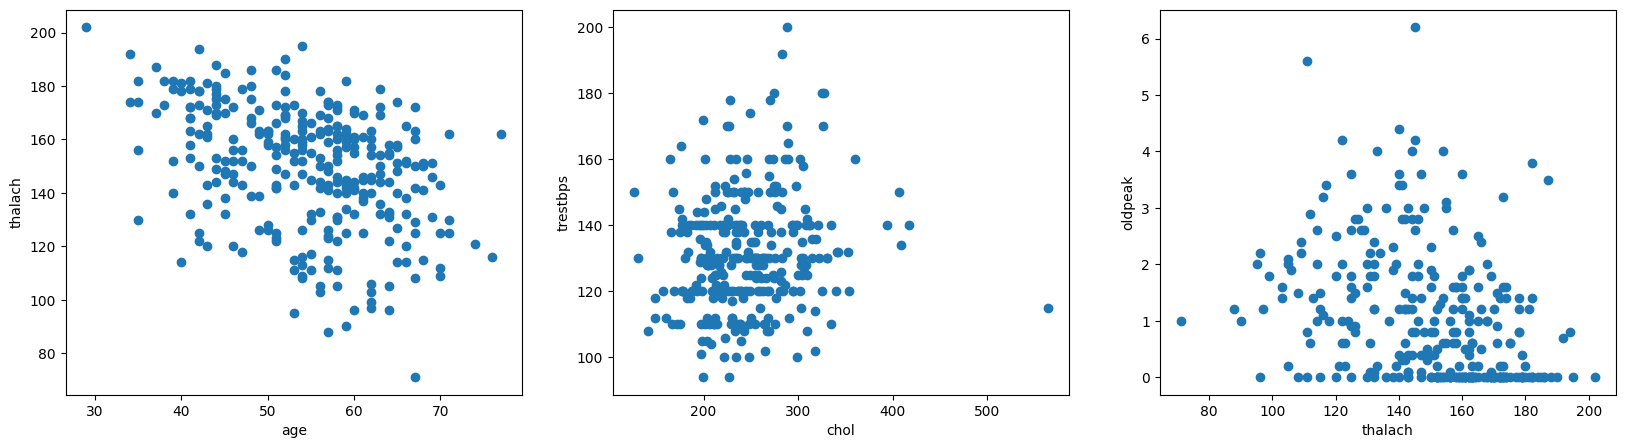

In [32]:
fig = plt.figure(figsize=(20, 5))  # Creamos una figura
ax1 = fig.add_subplot(131, projection='rectilinear')
ax2 = fig.add_subplot(132, projection='rectilinear')
ax3 = fig.add_subplot(133, projection='rectilinear')

ax1.scatter(pacientes['age'], pacientes['thalach'])
ax1.set_xlabel("age")
ax1.set_ylabel("thalach")

ax2.scatter(pacientes['chol'], pacientes['trestbps'])
ax2.set_xlabel("chol")
ax2.set_ylabel("trestbps")

ax3.scatter(pacientes['thalach'], pacientes['oldpeak'])
ax3.set_xlabel("thalach")
ax3.set_ylabel("oldpeak")

plt.show()

A diferencia de las viviendas, aquí no se ven grupos separados a simple vista: los pacientes forman una nube continua. Sí se aprecian algunas tendencias: la frecuencia cardíaca máxima (`thalach`) baja con la edad, y los pacientes con `oldpeak` alto suelen tener una frecuencia máxima más baja. También se ve que las variables tienen escalas muy distintas: el colesterol llega a más de 500, mientras que `oldpeak` no pasa de 7.

### 3. Preprocesado

Convertimos las 5 variables a una matriz, como hicimos con las viviendas.

Como k-means agrupa por distancias, si dejamos las variables como están, el colesterol (que varía en cientos) pesaría mucho más que `oldpeak` (que varía en unidades). Por eso las **escalamos**: a cada variable le restamos su media y la dividimos entre su desviación típica, de forma que todas quedan en una escala parecida. La media se calcula igual que los centroides en `actualiza_centr`:

In [33]:
pacientes_mat = pacientes[['age', 'trestbps', 'chol', 'thalach', 'oldpeak']].values

# Media y desviación típica de cada columna
media = np.sum(pacientes_mat, axis=0)/pacientes_mat.shape[0]
desviacion = np.sqrt(np.sum((pacientes_mat - media)**2, axis=0)/pacientes_mat.shape[0])

# Datos escalados
pacientes_esc = (pacientes_mat - media)/desviacion

### 4. Número de clusters (método del codo)

Usamos `KMeans`, porque nuestra función `k_medias` solo sirve para dos variables. Con `n_init=10` cada agrupamiento se repite con 10 inicializaciones distintas y se queda con la mejor, como hacía `k_medias_multi_ini`. Como coste usamos `inertia_ / len(pacientes)`, que mide la distancia cuadrática media de cada paciente a su centroide (a diferencia de `j()`, que no elevaba las distancias al cuadrado). Por eso, con $k=1$, el coste vale exactamente 5: al estar escaladas, cada una de las 5 variables aporta 1.

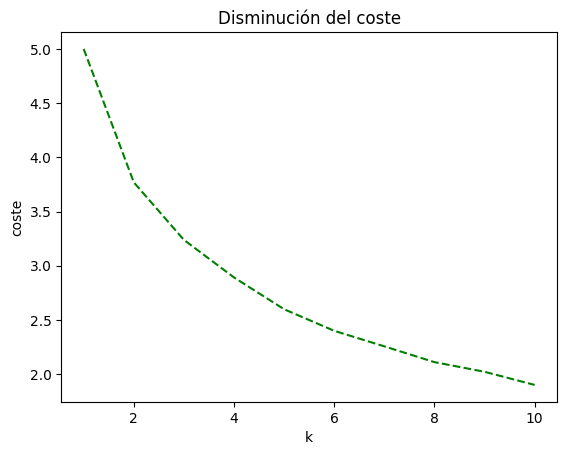

In [34]:
SEED_VALUE = 42

k_max = 10
custos_pacientes = []
for k in range(1, k_max+1):
    model = KMeans(n_clusters=k, n_init=10, random_state=SEED_VALUE)
    np.random.seed(SEED_VALUE)
    agrupamento = model.fit(pacientes_esc)
    custos_pacientes.append(agrupamento.inertia_ / len(pacientes))

plt.plot(range(1, k_max+1), custos_pacientes, '--', color="green")
plt.title("Disminución del coste")
plt.xlabel("k")
plt.ylabel("coste")
plt.show()

In [35]:
custos_pacientes

[5.0,
 3.769199699365323,
 3.2385327056107607,
 2.8919224806990003,
 2.5987298399997028,
 2.3997293919021967,
 2.2563076058029994,
 2.110985440891099,
 2.0218129236466753,
 1.900561928064265]

El coste baja mucho al pasar de 1 a 2 clusters (de 5,0 a 3,8) y bastante de 2 a 3 (de 3,8 a 3,2), pero a partir de ahí cada cluster nuevo mejora mucho menos. El codo no es tan claro como en las viviendas, pero lo situamos en **$k=3$**.

### 5. Agrupamiento final

In [36]:
model = KMeans(n_clusters=3, n_init=10, random_state=SEED_VALUE)
np.random.seed(SEED_VALUE)
agrupamento_pacientes = model.fit(pacientes_esc)
clusters_pacientes = agrupamento_pacientes.labels_

# Centroides en las unidades originales (deshacemos el escalado)
# Columnas: age, trestbps, chol, thalach, oldpeak
centroides_pacientes = agrupamento_pacientes.cluster_centers_*desviacion + media
centroides_pacientes

array([[ 59.11627907, 127.13953488, 228.41860465, 125.75581395,
          1.87790698],
       [ 48.82993197, 125.16326531, 235.65306122, 164.05442177,
          0.43877551],
       [ 60.47142857, 150.98571429, 292.32857143, 148.57142857,
          1.27142857]])

In [37]:
# Número de pacientes en cada cluster
pacientes_por_cluster = []
for i in range(3):
    pacientes_por_cluster.append(np.sum(clusters_pacientes==i))
pacientes_por_cluster

[np.int64(86), np.int64(147), np.int64(70)]

### 6. Visualización del agrupamiento

Como hay 5 variables, representamos el agrupamiento por pares de variables, con los mismos pares de antes. Cada color es un cluster y las **x** son los centroides:

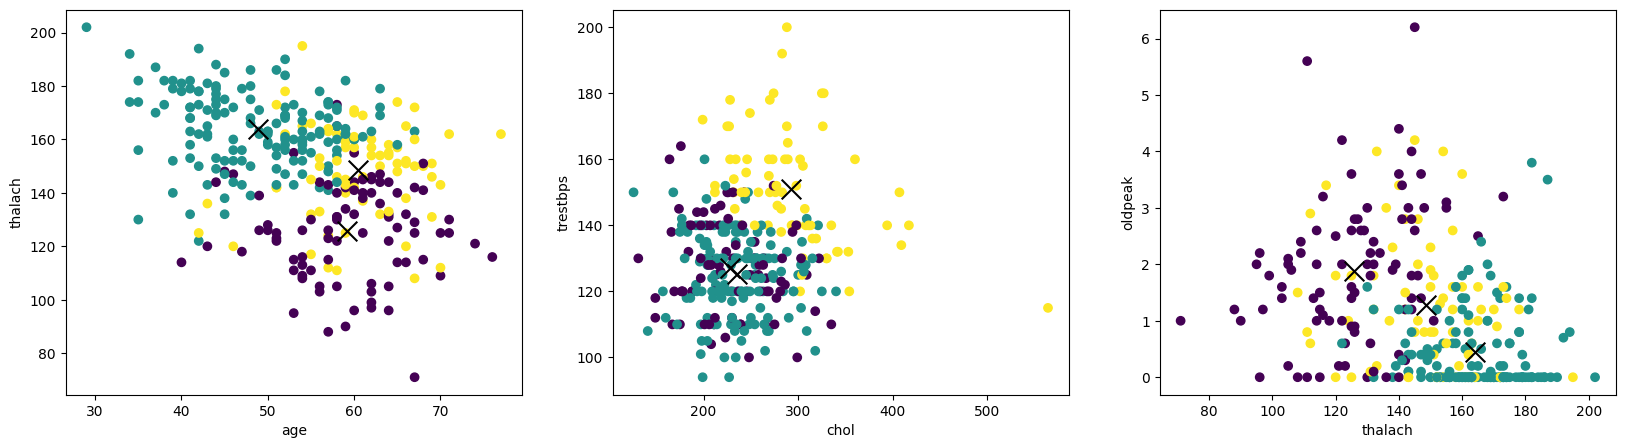

In [38]:
fig = plt.figure(figsize=(20, 5))  # Creamos una figura
ax1 = fig.add_subplot(131, projection='rectilinear')
ax2 = fig.add_subplot(132, projection='rectilinear')
ax3 = fig.add_subplot(133, projection='rectilinear')

ax1.scatter(pacientes['age'], pacientes['thalach'], c=clusters_pacientes)
ax1.scatter(centroides_pacientes[:, 0], centroides_pacientes[:, 3], s=200, marker='x', color='black')
ax1.set_xlabel("age")
ax1.set_ylabel("thalach")

ax2.scatter(pacientes['chol'], pacientes['trestbps'], c=clusters_pacientes)
ax2.scatter(centroides_pacientes[:, 2], centroides_pacientes[:, 1], s=200, marker='x', color='black')
ax2.set_xlabel("chol")
ax2.set_ylabel("trestbps")

ax3.scatter(pacientes['thalach'], pacientes['oldpeak'], c=clusters_pacientes)
ax3.scatter(centroides_pacientes[:, 3], centroides_pacientes[:, 4], s=200, marker='x', color='black')
ax3.set_xlabel("thalach")
ax3.set_ylabel("oldpeak")

plt.show()

### 7. Interpretación de los clusters

Viendo los centroides y las gráficas, los tres clusters corresponden a tres tipos de paciente:

- Cluster 0 (morado, 86 pacientes): mala respuesta al esfuerzo. Son mayores (unos 59 años de media), alcanzan una frecuencia cardíaca máxima baja (alrededor de 126) y tienen el `oldpeak` más alto (aproximadamente 1,9), aunque su presión y su colesterol son normales. Su corazón responde peor al esfuerzo, así que es el grupo de mayor riesgo.
- Cluster 1 (verde, 147 pacientes): jóvenes en buena forma. Son los más jóvenes (unos 49 años de media), con la frecuencia cardíaca máxima más alta (alrededor de 164) y casi sin alteración en el electrocardiograma (`oldpeak` de aproximadamente 0,4). Es el grupo más numeroso y el de menor riesgo.
- Cluster 2 (amarillo, 70 pacientes): presión y colesterol altos. También son mayores (unos 60 años de media), pero lo que los distingue es que tienen la presión (alrededor de 151) y el colesterol (alrededor de 292) más altos. Su respuesta al esfuerzo es intermedia.

En las gráficas se ve que la edad y la frecuencia cardíaca máxima (primera gráfica) separan el cluster 1 del 0, y que el colesterol y la presión (segunda gráfica) separan el cluster 2. Aun así, los grupos se solapan bastante, porque los pacientes no forman nubes separadas como las viviendas. Además, como no tenemos etiquetas, no podemos saber qué pacientes están realmente enfermos: los clusters describen perfiles de pacientes, no diagnósticos.

**************************************************************